In [ ]:
# PS 30: CBOW Using a Sample Text Corpus
# Import required libraries

import numpy as np
import re
import tensorflow as tf
import matplotlib.pyplot as plt

In [ ]:
# PS 30: Create a sample text corpus
# Using the same corpus as PS 28 and PS 29

text = """The speed of transmission is an important point of difference between the two viruses.
Influenza has a shorter median incubation period and a shorter serial interval than COVID-19.
The serial interval for COVID-19 is estimated to be 5-6 days, while for influenza it is 3 days.
This means influenza can spread faster than COVID-19.
Transmission before the appearance of symptoms is called pre-symptomatic transmission.
The reproductive number is the number of secondary infections generated from one infected individual."""

In [ ]:
# PS 30: Prepare the text data
# Convert text to lowercase, remove punctuation and tokenize

text = text.lower()

# Remove punctuation and special characters
text = re.sub(r'[^a-z ]', ' ', text)

# Split text into individual words
words = text.split()

# Repeat corpus to generate more training samples
words = words * 5

print("Tokenized Words:")
print(words)

print("\nTotal Words:", len(words))

Tokenized Words:
['the', 'speed', 'of', 'transmission', 'is', 'an', 'important', 'point', 'of', 'difference', 'between', 'the', 'two', 'viruses', 'influenza', 'has', 'a', 'shorter', 'median', 'incubation', 'period', 'and', 'a', 'shorter', 'serial', 'interval', 'than', 'covid', 'the', 'serial', 'interval', 'for', 'covid', 'is', 'estimated', 'to', 'be', 'days', 'while', 'for', 'influenza', 'it', 'is', 'days', 'this', 'means', 'influenza', 'can', 'spread', 'faster', 'than', 'covid', 'transmission', 'before', 'the', 'appearance', 'of', 'symptoms', 'is', 'called', 'pre', 'symptomatic', 'transmission', 'the', 'reproductive', 'number', 'is', 'the', 'number', 'of', 'secondary', 'infections', 'generated', 'from', 'one', 'infected', 'individual', 'the', 'speed', 'of', 'transmission', 'is', 'an', 'important', 'point', 'of', 'difference', 'between', 'the', 'two', 'viruses', 'influenza', 'has', 'a', 'shorter', 'median', 'incubation', 'period', 'and', 'a', 'shorter', 'serial', 'interval', 'than', 'c

In [ ]:
# PS 30: Create vocabulary from unique words
# Assign a unique numerical index to each word

vocab = sorted(set(words))

word_to_id = {word: i for i, word in enumerate(vocab)}

id_to_word = {i: word for word, i in word_to_id.items()}

print("Vocabulary:")
print(vocab)

print("\nVocabulary Size:", len(vocab))

print("\nWord to Index Mapping:")
print(word_to_id)

Vocabulary:
['a', 'an', 'and', 'appearance', 'be', 'before', 'between', 'called', 'can', 'covid', 'days', 'difference', 'estimated', 'faster', 'for', 'from', 'generated', 'has', 'important', 'incubation', 'individual', 'infected', 'infections', 'influenza', 'interval', 'is', 'it', 'means', 'median', 'number', 'of', 'one', 'period', 'point', 'pre', 'reproductive', 'secondary', 'serial', 'shorter', 'speed', 'spread', 'symptomatic', 'symptoms', 'than', 'the', 'this', 'to', 'transmission', 'two', 'viruses', 'while']

Vocabulary Size: 51

Word to Index Mapping:
{'a': 0, 'an': 1, 'and': 2, 'appearance': 3, 'be': 4, 'before': 5, 'between': 6, 'called': 7, 'can': 8, 'covid': 9, 'days': 10, 'difference': 11, 'estimated': 12, 'faster': 13, 'for': 14, 'from': 15, 'generated': 16, 'has': 17, 'important': 18, 'incubation': 19, 'individual': 20, 'infected': 21, 'infections': 22, 'influenza': 23, 'interval': 24, 'is': 25, 'it': 26, 'means': 27, 'median': 28, 'number': 29, 'of': 30, 'one': 31, 'period

In [ ]:
# PS 30: Generate CBOW training samples
# Use a fixed context window of 2 words on either side

window = 2

X = []
y = []

for i in range(window, len(words) - window):

    # Select two words before and two words after target
    context = [
        word_to_id[words[i-2]],
        word_to_id[words[i-1]],
        word_to_id[words[i+1]],
        word_to_id[words[i+2]]
    ]

    # Select the middle word as target
    target = word_to_id[words[i]]

    X.append(context)
    y.append(target)

X = np.array(X)
y = np.array(y)

print("Sample Context-Target Pairs:")

for i in range(5):
    print("Context:", [id_to_word[w] for w in X[i]])
    print("Target:", id_to_word[y[i]])
    print()

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

Sample Context-Target Pairs:
Context: ['the', 'speed', 'transmission', 'is']
Target: of

Context: ['speed', 'of', 'is', 'an']
Target: transmission

Context: ['of', 'transmission', 'an', 'important']
Target: is

Context: ['transmission', 'is', 'important', 'point']
Target: an

Context: ['is', 'an', 'point', 'of']
Target: important

Input Shape: (381, 4)
Target Shape: (381,)


In [ ]:
# PS 30: Build the CBOW neural network
# Use Embedding, GlobalAveragePooling1D and Dense layers

model = tf.keras.Sequential([

    # Convert word indices into 50-dimensional vectors
    tf.keras.layers.Embedding(
        input_dim=len(vocab),
        output_dim=50
    ),

    # Calculate average of context word embeddings
    tf.keras.layers.GlobalAveragePooling1D(),

    # Predict target word probabilities
    tf.keras.layers.Dense(
        len(vocab),
        activation='softmax'
    )
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# PS 30: Compile the CBOW model
# Use Adam optimizer and sparse categorical crossentropy

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
# PS 30: Train the CBOW model
# Learn word representations from context-target pairs

history = model.fit(
    X,
    y,
    epochs=200,
    batch_size=4,
    verbose=0
)

print("Training Loss:", history.history['loss'][-1])

print("Training Accuracy:", history.history['accuracy'][-1])

Training Loss: 0.019365651533007622
Training Accuracy: 0.9816272854804993


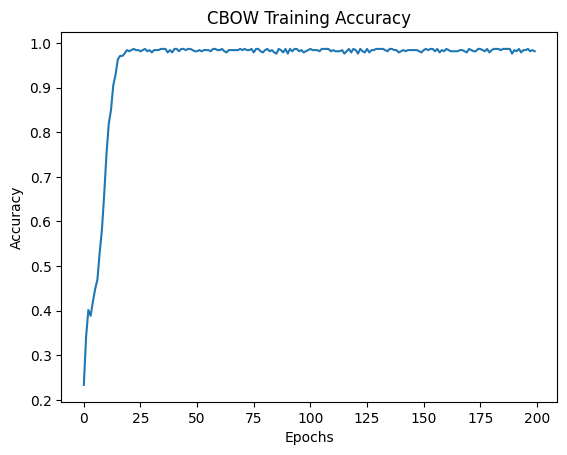

In [ ]:
# PS 30: Display training accuracy graph

plt.plot(history.history['accuracy'])

plt.title("CBOW Training Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.show()

In [ ]:
# PS 30: Define a function to predict the target word
# Accept four context words as input

def predict_word(context):

    # Convert context words into numerical indices
    ids = np.array([[word_to_id[word] for word in context]])

    # Predict target word probabilities
    prediction = model.predict(ids, verbose=0)

    # Find the index with the highest probability
    index = np.argmax(prediction)

    # Convert predicted index into the corresponding word
    return id_to_word[index]

In [ ]:
# PS 30: Test the trained CBOW model
# Predict a target word using given context words

context = ["is", "an", "point", "of"]

print("Context Words:", context)

print("Actual Target Word: important")

print("Predicted Target Word:", predict_word(context))

Context Words: ['is', 'an', 'point', 'of']
Actual Target Word: important
Predicted Target Word: important
